# Notebook 01 — Two-node thermal model of a data hall: derivation and numerical verification

**Project:** Dynamic Thermal Modelling and Energy-Efficient Cooling Optimization of AI Data Centres Using Optimal Control
**Stage 1 of the plan in `PROJECT_SPEC.md` (v0.2).** Model code: `src/thermal_model.py`.

<div style="background:#fff4e5;border-left:6px solid #eb6834;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>Scope of this notebook</b><br>
Physics model and <i>numerical verification</i> only. There are no controllers, no optimisation and <b>no energy-saving claims</b> here. Numerical verification shows that the code solves <i>our equations</i> correctly; it is <b>not real-world validation</b> of those equations. All parameters marked [ILL] are illustrative, not measured.
</div>

<div style="background:#f1f1ef;border-left:6px solid #6b6b66;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>AI acknowledgement</b><br>
This notebook and <code>src/thermal_model.py</code> were drafted by Claude (Anthropic), used through Claude Code, at the team's request on 28 Oct 2026, following <code>PROJECT_SPEC.md</code>. Every team member must review the equations and code and be able to explain them. Full log: <code>AI_USE_LOG.md</code>.
</div>

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

SRC = Path("..", "src").resolve()
sys.path.insert(0, str(SRC))
import thermal_model as tm

FIG_DIR = Path("..", "figures").resolve()
FIG_DIR.mkdir(exist_ok=True)

p = tm.Params()
results = []  # one row per verification check


def record(check_id, description, value, criterion, passed):
    # Print a PASS/FAIL line and stop the notebook on failure.
    results.append((check_id, description, value, criterion, bool(passed)))
    print(f"[{'PASS' if passed else 'FAIL'}] {check_id}: {description}\n        measured: {value}   criterion: {criterion}")
    assert passed, f"{check_id} failed"


print(f"numpy {np.__version__}, matplotlib {matplotlib.__version__}")
print("Parameters ([STD]: rho, c_p; everything else [ILL]):")
for name, val in vars(p).items():
    print(f"  {name:8s} = {val:.6g}")
print(f"  C_a      = {p.C_a:.6g} J/K   (derived: rho * c_p * V)")

numpy 2.5.4, matplotlib 3.11.2
Parameters ([STD]: rho, c_p; everything else [ILL]):
  rho      = 1.2
  c_p      = 1005
  V        = 3000
  C_s      = 2.5e+07
  UA_s     = 66666.7
  UA_e     = 2000
  Q_max    = 1.5e+06
  eta_II   = 0.45
  dT_ev    = 12
  dT_cd    = 8
  COP_cap  = 10
  C_a      = 3.618e+06 J/K   (derived: rho * c_p * V)


## 1. Variables, units and energy bookkeeping

| Symbol | Role | Meaning | Unit |
|---|---|---|---|
| $T_s$ | state | **lumped IT-equipment temperature**: one number for all servers/GPUs/heat sinks. Illustrative; *not* a GPU-die temperature | °C |
| $T_a$ | state | well-mixed room (inlet) air temperature | °C |
| $Q_c$ | input (control) | **heat removed** from the air by the cooling unit | W$_{th}$ |
| $P_{IT}$ | input (disturbance) | IT electrical power; all of it ends up as heat | W$_e$ |
| $T_{out}$ | input (disturbance) | outdoor air temperature | °C |
| $C_s$, $C_a$ | parameter | heat capacities of equipment and air ($C_a=\rho c_p V$) | J/K |
| $UA_s$, $UA_e$ | parameter | conductances equipment→air and air↔outdoors | W/K |

**Energy units.** The code works in joules. For reporting: $1\ \text{kWh} = 1000\ \text{W}\times 3600\ \text{s} = 3.6\times10^{6}\ \text{J}$.
Heat and electricity both use the joule, so we tag them: kWh$_{th}$ = heat, kWh$_e$ = electricity. They are linked only through the COP and are **never added together**.

Three energy accumulators are carried along with the state:

$$E_Q=\int Q_c\,dt\ \ (\text{heat removed}),\qquad E_{IT}=\int P_{IT}\,dt\ \ (\text{IT heat released}),\qquad E_{env}=\int UA_e\,(T_{out}-T_a)\,dt\ \ (\text{net heat in through the envelope}).$$

## 2. Derivation of the two energy-balance equations

<div style="background:#f3eefb;border-left:6px solid #7b52c4;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>Assumptions used (PROJECT_SPEC §5.2)</b><br>
A1 each node has one uniform temperature · A2 constant properties · A3 all IT electricity becomes heat · A4 equipment→air transfer $UA_s(T_s-T_a)$ · A5 cooling removes $Q_c$ instantly from the air · A8 envelope exchange $UA_e(T_{out}-T_a)$ · A9 no other internal gains.
</div>

For a lumped body with constant heat capacity $C$, the first law of thermodynamics reads
$C\,\dfrac{dT}{dt} = (\text{heat flowing in}) - (\text{heat flowing out})$, with every term in watts.

**Equation (1): IT equipment node.** Heat comes in as $P_{IT}$ (electricity fully dissipated) and leaves to the air by convection:

$$C_s\,\frac{dT_s}{dt} = P_{IT}(t) - UA_s\,(T_s-T_a). \tag{1}$$

*Plain English:* the equipment warms up whenever it makes heat faster than the air carries it away; the hotter it is relative to the air, the faster the air carries heat off.
*Units:* $\text{J/K}\cdot\text{K/s} = \text{W}$ on the left; W on the right.

**Equation (2): room air node.** The air receives heat from the equipment and through the walls, and the cooling unit takes heat out. The cooling unit draws air at $T_a$ and returns it colder at $T_{sup}$ with mass flow $\dot m$, so it removes $Q_c=\dot m\,c_p\,(T_a-T_{sup})\ge 0$. We use $Q_c$ directly as the control:

$$C_a\,\frac{dT_a}{dt} = UA_s\,(T_s-T_a) + UA_e\,(T_{out}-T_a) - Q_c(t). \tag{2}$$

*Plain English:* the room air warms when more heat arrives (from the servers and from outside) than the cooling unit removes. Air has a small heat capacity, so it reacts quickly.

<div style="background:#e8f1fc;border-left:6px solid #2a78d6;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>Matrix form (3)</b><br>
With $x=[T_s,\ T_a]^\top$, $u=Q_c$, $d=[P_{IT},\ T_{out}]^\top$: $\ \dot x = Ax + Bu + Ed$, where<br>$A=\begin{bmatrix}-UA_s/C_s & UA_s/C_s\\ UA_s/C_a & -(UA_s+UA_e)/C_a\end{bmatrix}$, $B=\begin{bmatrix}0\\ -1/C_a\end{bmatrix}$, $E=\begin{bmatrix}1/C_s & 0\\ 0 & UA_e/C_a\end{bmatrix}$. Every row has units K/s.
</div>

**Energy identity (4).** Adding (1) and (2), the internal transfer $UA_s(T_s-T_a)$ cancels:

$$\frac{d}{dt}\big(C_sT_s + C_aT_a\big) = \frac{dU}{dt} = P_{IT} + UA_e\,(T_{out}-T_a) - Q_c, \qquad\Rightarrow\qquad U(t_f)-U(0) = E_{IT} + E_{env} - E_Q. \tag{4}$$

**Check V0** confirms that the matrices reproduce the term-by-term equations, and that the unit conversions are right.

In [2]:
A, B, E, G = tm.system_matrices(p)
print("A [1/s] =\n", A)
print("B [K/J] =\n", B)
print("E [K/J, 1/s] =\n", E)

# V0a: matrix form vs term-by-term right-hand side at 1000 random points
rng = np.random.default_rng(1)
worst = 0.0
for _ in range(1000):
    x = rng.uniform(15.0, 45.0, 2)
    w = np.array([rng.uniform(0.0, p.Q_max), rng.uniform(0.0, 1.2e6), rng.uniform(20.0, 40.0)])
    worst = max(worst, np.max(np.abs(A @ x + G @ w - tm.rhs(p, x, w))))
record("V0a", "matrix form (3) vs equations (1)-(2), max |difference|", f"{worst:.2e} K/s", "< 1e-14 K/s", worst < 1e-14)

# V0b: unit conversions
one_MW_day_kWh = tm.J_to_kWh(1e6 * 86400)
ok = np.isclose(tm.J_to_kWh(3.6e6), 1.0) and np.isclose(tm.kWh_to_J(1.0), 3.6e6) and np.isclose(one_MW_day_kWh, 24000.0)
record("V0b", "1 kWh = 3.6e6 J; 1 MW for 24 h = 24 000 kWh", f"{one_MW_day_kWh:.1f} kWh", "exact", ok)

A [1/s] =
 [[-0.00266667  0.00266667]
 [ 0.01842639 -0.01897918]]
B [K/J] =
 [[ 0.00000000e+00]
 [-2.76395799e-07]]
E [K/J, 1/s] =
 [[4.00000000e-08 0.00000000e+00]
 [0.00000000e+00 5.52791598e-04]]
[PASS] V0a: matrix form (3) vs equations (1)-(2), max |difference|
        measured: 2.22e-16 K/s   criterion: < 1e-14 K/s
[PASS] V0b: 1 kWh = 3.6e6 J; 1 MW for 24 h = 24 000 kWh
        measured: 24000.0 kWh   criterion: exact


## 3. Algorithm: exact zero-order-hold (ZOH) propagation
<div style="background:#e7f7f0;border-left:6px solid #1baf7a;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>Augmented matrix exponential</b><br>
If the inputs $w=[Q_c,P_{IT},T_{out}]$ are constant on $[t_k,t_{k+1})$, the linear ODE has the exact solution $X_{k+1}=\Phi X_k+\Gamma w_k$. Both matrices come from <b>one</b> matrix exponential:<br>$\exp\!\left(\begin{bmatrix}F & H\\ 0 & 0\end{bmatrix}h\right)=\begin{bmatrix}\Phi & \Gamma\\ 0 & I\end{bmatrix}$, with $h=t_{k+1}-t_k$. We augment the state with the three energy accumulators, $X=[T_s,T_a,E_Q,E_{IT},E_{env}]$, so that their derivatives ($Q_c$, $P_{IT}$, $UA_e(T_{out}-T_a)$) are integrated <b>exactly and consistently</b> with the temperatures.
</div>

$$F=\begin{bmatrix}A & 0\\ K & 0\end{bmatrix},\quad K=\begin{bmatrix}0&0\\0&0\\0&-UA_e\end{bmatrix},\qquad
H=\begin{bmatrix}G\\ L\end{bmatrix},\quad G=[B\ \ E],\quad L=\mathrm{diag}(1,\,1,\,UA_e).$$

**Independent reference.** `scipy.integrate.solve_ivp` (implicit Radau, `rtol=1e-10`) integrates the same augmented ODE, but is **restarted at every input change**, so it never steps across a discontinuity.

**What is exact, and what is not:**

- Exact (up to round-off): the states and the three linear energy integrals, **provided** the inputs really are piecewise constant.
- **Not** made exact by this method: the cooling *electricity* $\int Q_c/\mathrm{COP}(T_a(t))\,dt$, because COP is nonlinear in $T_a$. That needs its own quadrature check later (L1).
- Also **not** established here: whether a 5-minute controller update is safe. That needs an inter-sample check later (L2).

### V1: zero load stays at rest
With $P_{IT}=0$, $Q_c=0$ and $T_{out}=T_s=T_a=25$ °C, no heat flows anywhere, so nothing may change.

In [3]:
T0 = 25.0
t_grid = np.arange(0.0, 24 * 3600 + 1, 300.0)
W = np.tile([0.0, 0.0, T0], (len(t_grid) - 1, 1))
X = tm.simulate_zoh(p, [T0, T0], t_grid, W)
drift = np.max(np.abs(X[:, :2] - T0))
acc = np.max(np.abs(X[:, 2:]))
# E_env is a difference of two large, cancelling terms (UA_e*T_out*t and UA_e*T_a*t), so its round-off
# scales with that size; we judge it relative to UA_e * T0 * t_f (about 4.3e9 J here).
scale = p.UA_e * T0 * t_grid[-1]
record("V1a", "zero load: max temperature drift over 24 h", f"{drift:.2e} K", "< 1e-12 K", drift < 1e-12)
record("V1b", "zero load: energy accumulators stay zero (relative to cancelling-term scale)", f"{acc:.2e} J = {acc/scale:.1e} x scale",
       "< 1e-9 x UA_e T0 t_f", acc / scale < 1e-9)

[PASS] V1a: zero load: max temperature drift over 24 h
        measured: 1.10e-13 K   criterion: < 1e-12 K
[PASS] V1b: zero load: energy accumulators stay zero (relative to cancelling-term scale)
        measured: 1.34e-05 J = 3.1e-15 x scale   criterion: < 1e-9 x UA_e T0 t_f


### V2: constant-load equilibrium
For constant inputs, setting $\dot x=0$ in (1)–(2) gives the analytic equilibrium

$$T_a^*=T_{out}+\frac{P_{IT}-Q_c}{UA_e},\qquad T_s^*=T_a^*+\frac{P_{IT}}{UA_s},$$

and the constant cooling that holds the air at a target $\bar T$ is $Q_c=P_{IT}+UA_e(T_{out}-\bar T)$.

We check four things:

1. the formula agrees with solving $Ax^*=-Gw$ numerically;
2. the residual $Ax^*+Gw$ vanishes;
3. starting at $x^*$, the state stays there for 24 h;
4. starting 5 K / −3 K away, the state returns to $x^*$. After $n$ slow time constants the distance should shrink roughly like $e^{-n}$.

In [4]:
P0, T_out0, T_target = 0.8e6, 30.0, 24.0                    # [ILL] operating point
Q0 = tm.holding_cooling(p, T_target, P0, T_out0)
w0 = np.array([Q0, P0, T_out0])
x_star = tm.equilibrium(p, Q0, P0, T_out0)
x_lin = np.linalg.solve(A, -G @ w0)
print(f"holding cooling Q_c = {Q0/1e6:.4f} MW_th;  x* = [T_s, T_a] = {x_star} degC;  T_s* - T_a* = {x_star[0]-x_star[1]:.3f} K (= P/UA_s = {P0/p.UA_s:.3f} K)")

record("V2a", "analytic equilibrium vs linear solve", f"{np.max(np.abs(x_star - x_lin)):.2e} K", "< 1e-9 K", np.allclose(x_star, x_lin, atol=1e-9, rtol=0))
res = np.max(np.abs(A @ x_star + G @ w0))
record("V2b", "residual |A x* + G w|", f"{res:.2e} K/s", "< 1e-15 K/s", res < 1e-15)

t_grid = np.arange(0.0, 24 * 3600 + 1, 300.0)
X = tm.simulate_zoh(p, x_star, t_grid, np.tile(w0, (len(t_grid) - 1, 1)))
drift = np.max(np.abs(X[:, :2] - x_star))
record("V2c", "start at x*: max drift over 24 h", f"{drift:.2e} K", "< 1e-9 K", drift < 1e-9)

tau_fast, tau_slow = tm.time_constants(p)
x_pert = x_star + np.array([5.0, -3.0])
print("distance from x* after n slow time constants (expected ~ e^-n x initial):")
for n in [0, 1, 3, 10, 30]:
    if n == 0:
        d = np.linalg.norm(x_pert - x_star)
    else:
        Phi, Gam = tm.zoh_step_matrices(p, n * tau_slow)
        d = np.linalg.norm((Phi @ np.r_[x_pert, 0, 0, 0] + Gam @ w0)[:2] - x_star)
    print(f"  n = {n:2d}: {d:.3e} K")
record("V2d", "perturbed start returns to x* after 30 tau_slow", f"{d:.2e} K", "< 1e-6 K", d < 1e-6)

holding cooling Q_c = 0.8120 MW_th;  x* = [T_s, T_a] = [36. 24.] degC;  T_s* - T_a* = 12.000 K (= P/UA_s = 12.000 K)
[PASS] V2a: analytic equilibrium vs linear solve
        measured: 2.63e-13 K   criterion: < 1e-9 K
[PASS] V2b: residual |A x* + G w|
        measured: 5.55e-17 K/s   criterion: < 1e-15 K/s
[PASS] V2c: start at x*: max drift over 24 h
        measured: 2.13e-14 K   criterion: < 1e-9 K
distance from x* after n slow time constants (expected ~ e^-n x initial):
  n =  0: 5.831e+00 K
  n =  1: 2.067e+00 K
  n =  3: 2.797e-01 K
  n = 10: 2.551e-04 K
  n = 30: 1.130e-08 K
[PASS] V2d: perturbed start returns to x* after 30 tau_slow
        measured: 1.13e-08 K   criterion: < 1e-6 K


### V3: eigenvalues and time constants
The eigenvalues of $A$ set how fast the hall responds. Two analytic facts:

- $\mathrm{tr}A=-\frac{UA_s}{C_s}-\frac{UA_s+UA_e}{C_a}<0$ and $\det A=\frac{UA_sUA_e}{C_sC_a}>0$, so the eigenvalues are $\lambda=\tfrac12\big(\mathrm{tr}A\pm\sqrt{(\mathrm{tr}A)^2-4\det A}\big)$.
- $D=\mathrm{diag}(\sqrt{C_s},\sqrt{C_a})$ makes $DAD^{-1}$ **symmetric**, so the eigenvalues are real (no oscillation). Together with the sign facts, both are negative, so the system is asymptotically stable.

Time constant $\tau=-1/\lambda$. The spec states $\tau_{fast}\approx 46$ s and $\tau_{slow}\approx 4.07$ h for these [ILL] parameters.

In [5]:
lam_sym = tm.eigenvalues(p)                                   # from the symmetric similar matrix
lam_A = np.sort(np.real_if_close(np.linalg.eigvals(A)))       # directly from A
trA = -p.UA_s / p.C_s - (p.UA_s + p.UA_e) / p.C_a
detA = p.UA_s * p.UA_e / (p.C_s * p.C_a)
lam_formula = np.sort((trA + np.array([-1.0, 1.0]) * np.sqrt(trA**2 - 4 * detA)) / 2)
print("eigenvalues [1/s]:  symmetric:", lam_sym, "  eig(A):", lam_A, "  formula:", lam_formula)

record("V3a", "eig(A) is real and equals symmetric-matrix eigenvalues",
       f"max rel diff {np.max(np.abs(lam_A - lam_sym) / np.abs(lam_sym)):.1e}", "< 1e-10, imag = 0",
       np.isrealobj(lam_A) and np.allclose(lam_A, lam_sym, rtol=1e-10, atol=0))
record("V3b", "trace/determinant formula matches", f"max rel diff {np.max(np.abs(lam_formula - lam_sym) / np.abs(lam_sym)):.1e}",
       "< 1e-8", np.allclose(lam_formula, lam_sym, rtol=1e-8, atol=0))
record("V3c", "both eigenvalues negative (asymptotically stable)", f"{lam_sym}", "< 0", np.all(lam_sym < 0))

tau_fast, tau_slow = tm.time_constants(p)
record("V3d", "fast time constant ~ 46 s", f"{tau_fast:.2f} s", "|tau - 46| < 0.5 s", abs(tau_fast - 46.0) < 0.5)
record("V3e", "slow time constant ~ 4.07 h", f"{tau_slow:.1f} s = {tau_slow/3600:.4f} h", "|tau - 4.07 h| < 0.01 h",
       abs(tau_slow / 3600 - 4.07) < 0.01)

print(f"\nstiffness ratio tau_slow / tau_fast = {tau_slow / tau_fast:.0f}")
print(f"forward-Euler stability limit 2/|lambda_fast| = {2 / abs(lam_sym[0]):.1f} s  (why we propagate with exact ZOH)")
print(f"compare: (C_s + C_a)/UA_e = {(p.C_s + p.C_a) / p.UA_e / 3600:.3f} h  (slow mode ~ total heat storage over envelope conductance)")

eigenvalues [1/s]:  symmetric: [-2.15775279e-02 -6.83169515e-05]   eig(A): [-2.15775279e-02 -6.83169515e-05]   formula: [-2.15775279e-02 -6.83169515e-05]
[PASS] V3a: eig(A) is real and equals symmetric-matrix eigenvalues
        measured: max rel diff 3.2e-14   criterion: < 1e-10, imag = 0
[PASS] V3b: trace/determinant formula matches
        measured: max rel diff 6.3e-15   criterion: < 1e-8
[PASS] V3c: both eigenvalues negative (asymptotically stable)
        measured: [-2.15775279e-02 -6.83169515e-05]   criterion: < 0
[PASS] V3d: fast time constant ~ 46 s
        measured: 46.34 s   criterion: |tau - 46| < 0.5 s
[PASS] V3e: slow time constant ~ 4.07 h
        measured: 14637.7 s = 4.0660 h   criterion: |tau - 4.07 h| < 0.01 h

stiffness ratio tau_slow / tau_fast = 316
forward-Euler stability limit 2/|lambda_fast| = 92.7 s  (why we propagate with exact ZOH)
compare: (C_s + C_a)/UA_e = 3.975 h  (slow mode ~ total heat storage over envelope conductance)


### V4: exact ZOH vs `solve_ivp`, on irregular piecewise-constant inputs
We use 96 intervals with random lengths (60–1800 s), random IT load (0.5–1.0 MW), random outdoor temperature (22–36 °C) and cooling close to, but not equal to, the holding value. This exercises arbitrary step lengths and every input channel.

`solve_ivp` is restarted at each input change. The two methods share no code apart from the matrices, so agreement is strong evidence that both are right.

In [6]:
rng = np.random.default_rng(2026)
n = 96
h = rng.uniform(60.0, 1800.0, n)
t_grid = np.concatenate([[0.0], np.cumsum(h)])
P = rng.uniform(0.5e6, 1.0e6, n)
T_out = rng.uniform(22.0, 36.0, n)
Q = np.clip(tm.holding_cooling(p, 24.0, P, T_out) + rng.uniform(-2e4, 2e4, n), 0.0, p.Q_max)
W4 = np.column_stack([Q, P, T_out])
x0 = tm.equilibrium(p, *W4[0])

X_zoh = tm.simulate_zoh(p, x0, t_grid, W4)
X_ivp = tm.simulate_ivp(p, x0, t_grid, W4)
print(f"horizon {t_grid[-1]/3600:.2f} h; T_a range {X_zoh[:,1].min():.2f}..{X_zoh[:,1].max():.2f} degC; "
      f"T_s range {X_zoh[:,0].min():.2f}..{X_zoh[:,0].max():.2f} degC")

dT = np.max(np.abs(X_zoh[:, :2] - X_ivp[:, :2]))
dE = np.max(np.abs(X_zoh[:, 2:] - X_ivp[:, 2:])) / X_zoh[-1, 3]
record("V4a", "ZOH vs solve_ivp: max temperature difference at breakpoints", f"{dT:.2e} K", "< 1e-6 K", dT < 1e-6)
record("V4b", "ZOH vs solve_ivp: max energy-accumulator difference / E_IT", f"{dE:.2e}", "< 1e-8", dE < 1e-8)

horizon 25.56 h; T_a range 19.00..27.62 degC; T_s range 31.74..37.47 degC
[PASS] V4a: ZOH vs solve_ivp: max temperature difference at breakpoints
        measured: 1.57e-10 K   criterion: < 1e-6 K
[PASS] V4b: ZOH vs solve_ivp: max energy-accumulator difference / E_IT
        measured: 2.93e-14   criterion: < 1e-8


### V5: energy conservation with consistently integrated energies
Equation (4) must hold: $U(t_f)-U(0)-(E_{IT}+E_{env}-E_Q)=0$.

The accumulators are integrated by the *same* method as the states, so the residual measures how well each method respects the physics. A sign or indexing error in $A$ would show up here.

### V6: contrast, sampled-state quadrature is not exact
If we instead estimate $E_{env}$ with the trapezoid rule on temperatures **sampled** every $h_s$ seconds, an error appears that shrinks as $h_s$ shrinks. This is reported, not pass/fail. It is the reason energies are propagated with the state, and a warning for the later electricity calculation.

In [7]:
E_IT = X_zoh[-1, 3]
res_zoh = tm.energy_balance_residual(p, X_zoh)
res_ivp = tm.energy_balance_residual(p, X_ivp)
print(f"E_IT = {tm.J_to_kWh(E_IT):.1f} kWh;  E_Q = {tm.J_to_kWh(X_zoh[-1,2]):.1f} kWh_th;  E_env = {tm.J_to_kWh(X_zoh[-1,4]):.2f} kWh_th;  "
      f"dU = {tm.J_to_kWh(tm.stored_energy(p, X_zoh[-1,:2]) - tm.stored_energy(p, X_zoh[0,:2])):.2f} kWh_th")
record("V5a", "energy balance (4), exact ZOH: |residual| / E_IT", f"{abs(res_zoh)/E_IT:.1e} ({res_zoh:.3f} J)", "< 1e-9", abs(res_zoh) / E_IT < 1e-9)
record("V5b", "energy balance (4), solve_ivp: |residual| / E_IT", f"{abs(res_ivp)/E_IT:.1e} ({res_ivp:.3f} J)", "< 1e-9", abs(res_ivp) / E_IT < 1e-9)

# V6: inputs change every 30 min; sample states every h_s seconds and integrate E_env with the trapezoid rule
rng6 = np.random.default_rng(7)
n6 = 48
P6 = rng6.uniform(0.5e6, 1.0e6, n6)
To6 = rng6.uniform(22.0, 36.0, n6)
Q6 = tm.holding_cooling(p, 24.0, P6, To6) + rng6.uniform(-2e5, 2e5, n6)
print("\nV6  sample step   trapezoid E_env error   (relative to |E_env|)")
for h_s in [1800.0, 300.0, 60.0, 10.0]:
    reps = int(1800.0 / h_s)
    t6 = np.arange(0.0, n6 * 1800.0 + 1, h_s)
    W6 = np.repeat(np.column_stack([Q6, P6, To6]), reps, axis=0)
    X6 = tm.simulate_zoh(p, tm.equilibrium(p, *W6[0]), t6, W6)
    E_env_exact = X6[-1, 4]
    T_a_mid = 0.5 * (X6[:-1, 1] + X6[1:, 1])
    E_env_trap = np.sum(p.UA_e * (W6[:, 2] - T_a_mid) * h_s)
    err = E_env_trap - E_env_exact
    print(f"    {h_s:6.0f} s      {tm.J_to_kWh(err):+10.4f} kWh_th          {abs(err)/abs(E_env_exact):.1e}")

E_IT = 19171.8 kWh;  E_Q = 19418.1 kWh_th;  E_env = 263.46 kWh_th;  dU = 17.15 kWh_th
[PASS] V5a: energy balance (4), exact ZOH: |residual| / E_IT
        measured: 1.4e-14 (0.001 J)   criterion: < 1e-9
[PASS] V5b: energy balance (4), solve_ivp: |residual| / E_IT
        measured: 1.1e-14 (-0.001 J)   criterion: < 1e-9

V6  sample step   trapezoid E_env error   (relative to |E_env|)
      1800 s         -2.7596 kWh_th          6.1e-03
       300 s         -0.2242 kWh_th          5.0e-04
        60 s         -0.0129 kWh_th          2.9e-05
        10 s         -0.0004 kWh_th          8.1e-07


### V7: COP model and its valid domain (PROJECT_SPEC §5.5)
$\mathrm{COP}=\eta_{II}\,T_{ev}/(T_{cd}-T_{ev})$, with $T_{ev}=T_a-\Delta T_{ev}+273.15$ and $T_{cd}=T_{out}+\Delta T_{cd}+273.15$, both in K. All parameter values are illustrative.

- The formula needs a positive "lift" $T_{cd}-T_{ev}$. We restrict it further to $\mathrm{COP}\le\mathrm{COP}_{cap}$.
- That restriction gives a minimum outdoor temperature for each room temperature. Below it, a real plant would use free cooling, which we do not model, so the code **raises an error** instead of silently capping.
- The COP is not used in any calculation in this notebook. We only check that it behaves as documented.

In [8]:
for Ta, To in [(18, 30), (22, 30), (27, 30), (22, 36), (22, 32)]:
    print(f"  T_a = {Ta} degC, T_out = {To} degC  ->  COP = {tm.cop(p, Ta, To):.3f}")

Ta_grid, To_grid = np.meshgrid(np.linspace(18, 27, 19), np.linspace(20.5, 40, 40))
C = tm.cop(p, Ta_grid, To_grid)
record("V7a", "inside domain: COP rises with T_a and falls with T_out",
       f"min dCOP(T_a) {np.diff(C, axis=1).min():.3f}, max dCOP(T_out) {np.diff(C, axis=0).max():.3f}", "> 0 and < 0",
       np.all(np.diff(C, axis=1) > 0) and np.all(np.diff(C, axis=0) < 0))

tmin18, tmin27 = tm.min_valid_T_out(p, 18.0), tm.min_valid_T_out(p, 27.0)
record("V7b", "minimum valid T_out at T_a = 18 / 27 degC", f"{tmin18:.2f} / {tmin27:.2f} degC", "~10.6 / ~20.0 degC (spec §5.5)",
       abs(tmin18 - 10.56) < 0.01 and abs(tmin27 - 19.97) < 0.01)
record("V7c", "COP equals COP_cap exactly at the domain edge", f"{tm.cop(p, 27.0, tmin27 + 1e-12):.6f}", "10.000000",
       np.isclose(tm.cop(p, 27.0, tmin27 + 1e-12), p.COP_cap))
try:
    tm.cop(p, 27.0, 15.0)
    raised = False
except tm.COPDomainError as err:
    raised = True
    print("  outside domain (T_a = 27, T_out = 15):", err)
record("V7d", "outside domain raises COPDomainError", str(raised), "True", raised)

  T_a = 18 degC, T_out = 30 degC  ->  COP = 3.926
  T_a = 22 degC, T_out = 30 degC  ->  COP = 4.551
  T_a = 27 degC, T_out = 30 degC  ->  COP = 5.638
  T_a = 22 degC, T_out = 36 degC  ->  COP = 3.748
  T_a = 22 degC, T_out = 32 degC  ->  COP = 4.247
[PASS] V7a: inside domain: COP rises with T_a and falls with T_out
        measured: min dCOP(T_a) 0.041, max dCOP(T_out) -0.036   criterion: > 0 and < 0
[PASS] V7b: minimum valid T_out at T_a = 18 / 27 degC
        measured: 10.56 / 19.97 degC   criterion: ~10.6 / ~20.0 degC (spec §5.5)
[PASS] V7c: COP equals COP_cap exactly at the domain edge
        measured: 10.000000   criterion: 10.000000
  outside domain (T_a = 27, T_out = 15): COP model outside its domain: lift 8.000 K < required 12.967 K
[PASS] V7d: outside domain raises COPDomainError
        measured: True   criterion: True


### V10: invalid-input regression tests
The model must **refuse** impossible or malformed inputs loudly instead of returning a misleading number. Each test below passes only if the stated exception is raised. Any other exception, or a returned value, counts as a failure.

- **`cop()`** raises `COPDomainError` for: non-finite temperatures; evaporator absolute temperature $T_{ev}\le 0$ K; zero or negative lift; and (unchanged, V7d) COP above the cap.
  *Why the $T_{ev}$ check matters:* at $T_a=-300$ °C we get $T_{ev}\approx-38.9$ K. Then the cap test $\text{lift}\ge\eta_{II}T_{ev}/\mathrm{COP}_{cap}$ is satisfied trivially, because the right-hand side is negative. The previous version therefore returned a physically impossible $\mathrm{COP}\approx-0.050$.
- **`simulate_zoh()` and `simulate_ivp()`** raise `ValueError` for: NaN or inf in the state, time or inputs; time grids that run backwards, are non-monotonic or repeat a point; wrong input or state shapes; and too few time points. These checks are explicit `if … raise ValueError` statements, not `assert`, because Python skips `assert` when run with `-O`.

In [9]:
def expect_error(check_id, description, fn, exc_type):
    # PASS only if fn() raises exc_type; a different exception or a normal return is a FAIL.
    try:
        fn()
    except exc_type as err:
        record(check_id, description, f"{exc_type.__name__}: {err}", f"raises {exc_type.__name__}", True)
        return
    except Exception as err:
        record(check_id, description, f"wrong exception {type(err).__name__}: {err}", f"raises {exc_type.__name__}", False)
        return
    record(check_id, description, "no exception raised", f"raises {exc_type.__name__}", False)


cop_cases = [
    ("impossible evaporator temperature (T_a = -300 degC -> T_ev < 0 K)", lambda: tm.cop(p, -300.0, 30.0)),
    ("NaN room temperature", lambda: tm.cop(p, np.nan, 30.0)),
    ("infinite outdoor temperature", lambda: tm.cop(p, 24.0, np.inf)),
    ("NaN inside an array of otherwise valid temperatures", lambda: tm.cop(p, np.array([22.0, np.nan]), 30.0)),
    ("zero lift (T_out = T_a - dT_ev - dT_cd)", lambda: tm.cop(p, 27.0, 27.0 - p.dT_ev - p.dT_cd)),
    ("negative lift (T_out = -1 degC, T_a = 27 degC)", lambda: tm.cop(p, 27.0, -1.0)),
]
for i, (desc, fn) in enumerate(cop_cases, start=1):
    expect_error(f"V10.c{i}", "cop(): " + desc, fn, tm.COPDomainError)

# a small valid baseline problem, then corrupt one thing at a time
t_ok = np.array([0.0, 300.0, 600.0])
W_ok = np.array([[0.8e6, 0.8e6, 30.0], [0.8e6, 0.8e6, 30.0]])
x_ok = np.array([36.0, 24.0])
for fn in (tm.simulate_zoh, tm.simulate_ivp):          # the valid baseline must still run
    fn(p, x_ok, t_ok, W_ok)

W_nan = W_ok.copy(); W_nan[1, 1] = np.nan
sim_cases = [
    ("NaN in inputs W", lambda f: f(p, x_ok, t_ok, W_nan)),
    ("NaN in initial state x0", lambda f: f(p, [np.nan, 24.0], t_ok, W_ok)),
    ("inf in time grid", lambda f: f(p, x_ok, [0.0, 300.0, np.inf], W_ok)),
    ("backwards time grid", lambda f: f(p, x_ok, [600.0, 300.0, 0.0], W_ok)),
    ("non-monotonic time grid", lambda f: f(p, x_ok, [0.0, 300.0, 200.0, 600.0], np.vstack([W_ok, W_ok[:1]]))),
    ("repeated time point (zero-length interval)", lambda f: f(p, x_ok, [0.0, 300.0, 300.0], W_ok)),
    ("W with one row too many", lambda f: f(p, x_ok, t_ok, np.vstack([W_ok, W_ok[:1]]))),
    ("W with 2 columns instead of 3", lambda f: f(p, x_ok, t_ok, W_ok[:, :2])),
    ("x0 with 3 entries instead of 2", lambda f: f(p, [36.0, 24.0, 0.0], t_ok, W_ok)),
    ("time grid with a single point", lambda f: f(p, x_ok, [0.0], W_ok[:0])),
]
for tag, fn_sim in (("z", tm.simulate_zoh), ("i", tm.simulate_ivp)):
    for i, (desc, case) in enumerate(sim_cases, start=1):
        expect_error(f"V10.{tag}{i}", f"{fn_sim.__name__}(): {desc}", lambda case=case, fn_sim=fn_sim: case(fn_sim), ValueError)
expect_error("V10.i11", "simulate_ivp(): eval_step = 0", lambda: tm.simulate_ivp(p, x_ok, t_ok, W_ok, eval_step=0.0), ValueError)

[PASS] V10.c1: cop(): impossible evaporator temperature (T_a = -300 degC -> T_ev < 0 K)
        measured: COPDomainError: evaporator absolute temperature must be > 0 K; got T_ev = -38.85 K (T_a = -300.00 degC)   criterion: raises COPDomainError
[PASS] V10.c2: cop(): NaN room temperature
        measured: COPDomainError: non-finite temperature (NaN or inf) passed to cop()   criterion: raises COPDomainError
[PASS] V10.c3: cop(): infinite outdoor temperature
        measured: COPDomainError: non-finite temperature (NaN or inf) passed to cop()   criterion: raises COPDomainError
[PASS] V10.c4: cop(): NaN inside an array of otherwise valid temperatures
        measured: COPDomainError: non-finite temperature (NaN or inf) passed to cop()   criterion: raises COPDomainError
[PASS] V10.c5: cop(): zero lift (T_out = T_a - dT_ev - dT_cd)
        measured: COPDomainError: temperature lift T_cd - T_ev must be > 0 K; got 0.00 K   criterion: raises COPDomainError
[PASS] V10.c6: cop(): negative lift (T

[PASS] V10.z1: simulate_zoh(): NaN in inputs W
        measured: ValueError: W contains non-finite values (NaN or inf)   criterion: raises ValueError
[PASS] V10.z2: simulate_zoh(): NaN in initial state x0
        measured: ValueError: x0 contains non-finite values (NaN or inf)   criterion: raises ValueError
[PASS] V10.z3: simulate_zoh(): inf in time grid
        measured: ValueError: t_grid contains non-finite values (NaN or inf)   criterion: raises ValueError
[PASS] V10.z4: simulate_zoh(): backwards time grid
        measured: ValueError: t_grid must be strictly increasing; t[1] = 300.0 <= t[0] = 600.0   criterion: raises ValueError
[PASS] V10.z5: simulate_zoh(): non-monotonic time grid
        measured: ValueError: t_grid must be strictly increasing; t[2] = 200.0 <= t[1] = 300.0   criterion: raises ValueError
[PASS] V10.z6: simulate_zoh(): repeated time point (zero-length interval)
        measured: ValueError: t_grid must be strictly increasing; t[2] = 300.0 <= t[1] = 300.0   criter

## 4. Illustrative transient: a load step with steady-state-matched cooling
<div style="background:#fff4e5;border-left:6px solid #eb6834;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>What this experiment is, and is not</b><br>
An <b>open-loop</b> input schedule chosen to show the model's two time-scales. It is not a controller, and it makes no claim about energy or savings. All numbers are model outputs with [ILL] parameters.
</div>

**Scenario.** Outdoor temperature is fixed at 30 °C.

1. The hall starts in equilibrium at $P_{IT}=0.6$ MW, with the cooling that holds $T_a=24$ °C.
2. At $t=1$ h the IT load steps to 1.0 MW. **At the same instant** the cooling steps to the new steady-state holding value $Q_c=P_{IT}+UA_e(T_{out}-24)$.
3. At $t=7$ h both step back.

**Question.** If cooling is matched exactly to the new steady state, does the air stay at 24 °C?

**Method.** Exact ZOH on a 10 s output grid. The curves are cross-checked point by point against `solve_ivp`, restarted at the two step times. The dotted grey lines show the illustrative 18–27 °C air band and the illustrative 40 °C $T_s$ limit.

In [10]:
T_out_c, T_hold = 30.0, 24.0               # [ILL]
P_lo, P_hi = 0.6e6, 1.0e6                  # [ILL]
t_up, t_down, t_end = 1 * 3600.0, 7 * 3600.0, 12 * 3600.0
Q_lo, Q_hi = tm.holding_cooling(p, T_hold, P_lo, T_out_c), tm.holding_cooling(p, T_hold, P_hi, T_out_c)

dt = 10.0
t = np.arange(0.0, t_end + dt / 2, dt)
high = (t[:-1] >= t_up) & (t[:-1] < t_down)
W_tr = np.column_stack([np.where(high, Q_hi, Q_lo), np.where(high, P_hi, P_lo), np.full(len(t) - 1, T_out_c)])
x0 = tm.equilibrium(p, Q_lo, P_lo, T_out_c)
X_tr = tm.simulate_zoh(p, x0, t, W_tr)

# independent cross-check: solve_ivp on the three constant pieces, sampled on the same 10 s grid
breaks = np.array([0.0, t_up, t_down, t_end])
W_pieces = np.array([[Q_lo, P_lo, T_out_c], [Q_hi, P_hi, T_out_c], [Q_lo, P_lo, T_out_c]])
_, t_dense, X_dense = tm.simulate_ivp(p, x0, breaks, W_pieces, eval_step=dt)
idx = np.rint(t_dense / dt).astype(int)
dT_tr = np.max(np.abs(X_tr[idx, :2] - X_dense[:, :2]))
record("V8", "transient: ZOH vs solve_ivp on every 10 s point", f"{dT_tr:.2e} K", "< 1e-6 K", dT_tr < 1e-6)
res_tr = tm.energy_balance_residual(p, X_tr)
record("V9", "transient: energy balance |residual| / E_IT", f"{abs(res_tr)/X_tr[-1,3]:.1e}", "< 1e-9", abs(res_tr) / X_tr[-1, 3] < 1e-9)

T_s, T_a = X_tr[:, 0], X_tr[:, 1]
th = t / 3600
up = (t >= t_up) & (t < t_down)
dn = t >= t_down
i_min = np.argmin(np.where(up, T_a, np.inf))
i_max = np.argmax(np.where(dn, T_a, -np.inf))
at = lambda hours: int(round(hours * 3600 / dt))
print(f"\nQ_c holding values: {Q_lo/1e6:.3f} MW_th (0.6 MW load) and {Q_hi/1e6:.3f} MW_th (1.0 MW load)")
print(f"after step up:   min T_a = {T_a[i_min]:.2f} degC, {(t[i_min]-t_up)/60:.1f} min after the step")
print(f"                 T_a = {T_a[at(2)]:.2f} degC at 1 h after, {T_a[at(7)-1]:.2f} degC at 6 h after (target 24.00)")
print(f"                 T_s = {T_s[at(7)-1]:.2f} degC at 6 h after (new equilibrium {tm.equilibrium(p, Q_hi, P_hi, T_out_c)[0]:.2f})")
print(f"after step down: max T_a = {T_a[i_max]:.2f} degC, {(t[i_max]-t_down)/60:.1f} min after the step; T_a = {T_a[-1]:.2f} degC at 12 h")
print(f"energy needed to warm the equipment by dP/UA_s = {(P_hi-P_lo)/p.UA_s:.1f} K: C_s*dT = {tm.J_to_kWh(p.C_s*(P_hi-P_lo)/p.UA_s):.1f} kWh_th")

[PASS] V8: transient: ZOH vs solve_ivp on every 10 s point
        measured: 7.84e-09 K   criterion: < 1e-6 K
[PASS] V9: transient: energy balance |residual| / E_IT
        measured: 1.5e-11   criterion: < 1e-9

Q_c holding values: 0.612 MW_th (0.6 MW load) and 1.012 MW_th (1.0 MW load)
after step up:   min T_a = 18.97 degC, 4.5 min after the step
                 T_a = 19.98 degC at 1 h after, 22.82 degC at 6 h after (target 24.00)
                 T_s = 37.79 degC at 6 h after (new equilibrium 39.00)
after step down: max T_a = 27.88 degC, 4.7 min after the step; T_a = 25.16 degC at 12 h
energy needed to warm the equipment by dP/UA_s = 6.0 K: C_s*dT = 41.7 kWh_th


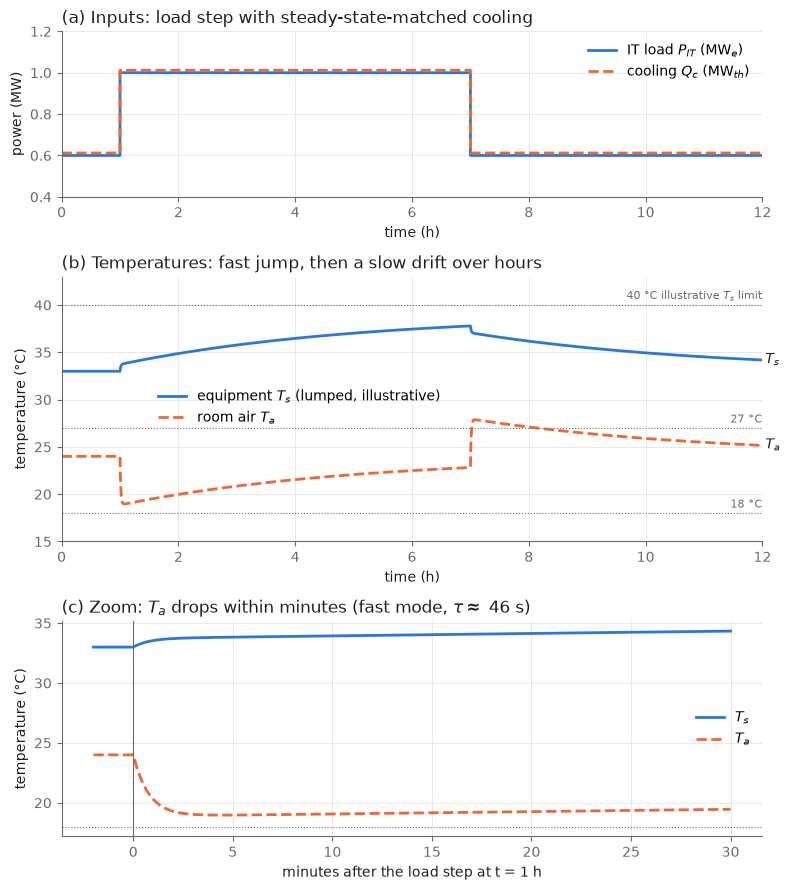

saved: /home/melenin/Projects/MM_proj/figures/fig01_transient_illustrative.eps


In [11]:
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1f1f1d", "#6b6b66", "#e4e4e0"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False})

fig, axs = plt.subplots(3, 1, figsize=(8.0, 9.0), gridspec_kw={"height_ratios": [1, 1.6, 1.3]})

# (a) inputs
ax = axs[0]
ax.step(th[:-1], W_tr[:, 1] / 1e6, where="post", color=BLUE, lw=2, label=r"IT load $P_{IT}$ (MW$_e$)")
ax.step(th[:-1], W_tr[:, 0] / 1e6, where="post", color=ORANGE, lw=2, ls="--", label=r"cooling $Q_c$ (MW$_{th}$)")
ax.set_ylabel("power (MW)")
ax.set_ylim(0.4, 1.2)
ax.set_title("(a) Inputs: load step with steady-state-matched cooling", loc="left", color=INK)
ax.legend(loc="upper right", frameon=False)

# (b) temperatures over 12 h
ax = axs[1]
ax.plot(th, T_s, color=BLUE, lw=2, label=r"equipment $T_s$ (lumped, illustrative)")
ax.plot(th, T_a, color=ORANGE, lw=2, ls="--", label=r"room air $T_a$")
for y, txt in [(18, "18 °C"), (27, "27 °C"), (40, r"40 °C illustrative $T_s$ limit")]:
    ax.axhline(y, color=MUTED, lw=0.8, ls=":")
    ax.text(12.0, y + 0.3, txt, color=MUTED, fontsize=8, ha="right", va="bottom")
ax.text(12.05, T_s[-1], r"$T_s$", color=INK, va="center")
ax.text(12.05, T_a[-1], r"$T_a$", color=INK, va="center")
ax.set_ylabel("temperature (°C)")
ax.set_ylim(15, 43)
ax.set_title("(b) Temperatures: fast jump, then a slow drift over hours", loc="left", color=INK)
ax.legend(loc="upper left", frameon=False, bbox_to_anchor=(0.12, 0.62))

# (c) zoom on the first 30 minutes after the step up
ax = axs[2]
zoom = (t >= t_up - 120) & (t <= t_up + 1800)
tz = (t[zoom] - t_up) / 60
ax.plot(tz, T_s[zoom], color=BLUE, lw=2, label=r"$T_s$")
ax.plot(tz, T_a[zoom], color=ORANGE, lw=2, ls="--", label=r"$T_a$")
ax.axhline(18, color=MUTED, lw=0.8, ls=":")
ax.axvline(0, color=MUTED, lw=0.8)
ax.set_xlabel("minutes after the load step at t = 1 h")
ax.set_ylabel("temperature (°C)")
ax.set_title(r"(c) Zoom: $T_a$ drops within minutes (fast mode, $\tau \approx$ 46 s)", loc="left", color=INK)
ax.legend(loc="right", frameon=False)

for ax in axs[:2]:
    ax.set_xlabel("time (h)")
    ax.set_xlim(0, 12)
for ax in axs:
    ax.grid(True, color=GRID, lw=0.6)
    ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig01_transient_illustrative.eps", format="eps")
fig.savefig(FIG_DIR / "fig01_transient_illustrative.png", dpi=150)
plt.show()
print("saved:", FIG_DIR / "fig01_transient_illustrative.eps")

### Interpretation
<div style="background:#fdf6e3;border-left:6px solid #c98500;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>What the figure shows (model behaviour, illustrative parameters)</b><br>
<ol>
<li><b>Matching the cooling to the new steady state does <i>not</i> hold the air at 24 °C.</b> About 4.5 minutes after the load step, $T_a$ falls to about 19.0 °C (printed above). The extra cooling acts on the air immediately. The extra IT heat reaches the air only after the equipment has warmed by $\Delta P/UA_s = 6$ K. Until then, the air is over-cooled. This drop is the fast mode ($\tau \approx 46$ s), seen in panel (c).</li>
<li><b>Recovery is slow because of stored energy.</b> Warming the equipment by 6 K needs $C_s \times 6\ \text{K} \approx 41.7$ kWh$_{th}$ of stored heat. With cooling matched to the load, the only net heat inflow left is $dU/dt = UA_e\,(24 - T_a)$, roughly 10 kW at a 5 K deficit. So recovery runs on the slow mode ($\tau \approx 4.07$ h). After 6 hours, $T_a$ is still about 1.2 K below target (22.82 °C), and $T_s$ (37.79 °C) has not reached its new equilibrium (39.00 °C).</li>
<li><b>The step down mirrors this.</b> $T_a$ jumps to about 27.9 °C within about 5 minutes, above the illustrative 27 °C band edge, and is still 25.16 °C at 12 h.</li>
<li><b>What this means for the next stages (expectations, not results):</b>
<ul>
<li>A steady-state schedule alone cannot regulate temperature, so feedback control is needed.</li>
<li>Air temperature moves by several kelvin within minutes, so a 5-minute controller update interval must be <i>checked</i> (L2), not assumed safe.</li>
</ul></li>
</ol>
No COP or electricity is computed here, so this figure says nothing about energy use or savings. All parameters are illustrative.

</div>

## 5. Summary of verification checks

In [12]:
import re

groups = [
    ("Equilibria (zero load, constant load)", ["V1", "V2"]),
    ("Energy conservation", ["V5", "V9"]),
    ("ZOH vs solve_ivp", ["V4", "V8"]),
    ("Time constants / eigenvalues", ["V3"]),
    ("Invalid-input regression tests", ["V10"]),
    ("Matrix form and units", ["V0"]),
    ("COP valid domain (valid cases)", ["V7"]),
]
base = lambda cid: re.match(r"V\d+", cid).group()
lines = ["STAGE 1 VERIFICATION SUMMARY (fresh kernel)", "-" * 60]
for name, prefixes in groups:
    rows = [r for r in results if base(r[0]) in prefixes]
    n_ok = sum(r[4] for r in rows)
    lines.append(f"{'PASS' if n_ok == len(rows) else 'FAIL'}  {name:40s} {n_ok:2d}/{len(rows):2d}")
key = {"V2d": "decay", "V3d": "tau_fast", "V3e": "tau_slow", "V4a": "max dT", "V5a": "ZOH residual/E_IT",
       "V5b": "ivp residual/E_IT", "V8": "transient dT", "V9": "transient residual/E_IT"}
lines.append("-" * 60)
for cid, desc, val, crit, ok in results:
    if cid in key:
        lines.append(f"  {cid:4s} {key[cid]:24s} {val}")
lines.append("-" * 60)
lines.append(f"TOTAL {sum(r[4] for r in results)}/{len(results)} checks passed")
print("\n".join(lines))
assert sum(len([r for r in results if base(r[0]) in g[1]]) for g in groups) == len(results), "ungrouped check"

STAGE 1 VERIFICATION SUMMARY (fresh kernel)
------------------------------------------------------------
PASS  Equilibria (zero load, constant load)     6/ 6
PASS  Energy conservation                       3/ 3
PASS  ZOH vs solve_ivp                          3/ 3
PASS  Time constants / eigenvalues              5/ 5
PASS  Invalid-input regression tests           27/27
PASS  Matrix form and units                     2/ 2
PASS  COP valid domain (valid cases)            4/ 4
------------------------------------------------------------
  V2d  decay                    1.13e-08 K
  V3d  tau_fast                 46.34 s
  V3e  tau_slow                 14637.7 s = 4.0660 h
  V4a  max dT                   1.57e-10 K
  V5a  ZOH residual/E_IT        1.4e-14 (0.001 J)
  V5b  ivp residual/E_IT        1.1e-14 (-0.001 J)
  V8   transient dT             7.84e-09 K
  V9   transient residual/E_IT  1.5e-11
------------------------------------------------------------
TOTAL 50/50 checks passed


## 6. What this notebook does **not** show, and what comes next
<div style="background:#fff4e5;border-left:6px solid #eb6834;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>Limits of Stage 1</b><br>
<ul><li><b>Verification, not validation:</b> nothing here compares the model with a real data hall.</li><li>Exact state propagation does <b>not</b> make the cooling-electricity integral $\int Q_c/\mathrm{COP}(T_a)\,dt$ exact. That needs check L1.</li><li>Nothing here shows that a 5-minute controller update is safe. Panel (c) shows that $T_a$ moves by several kelvin within minutes, so inter-sample behaviour must be checked (L2).</li><li>$T_s$ and its 40 °C limit are illustrative modelling quantities, not measured or certified limits.</li></ul><b>Next stage (after team review):</b> fixed-setpoint and load-adaptive PI controllers, with checks L2, L4 and L6.
</div>